# Reinforcement Learning 

Trabalho realizado por:
- Francisco Lopes nº111358
- Raul Azevedo nº111479

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

## Exercício 1

### Alínea a - Função de transição de estados

A função `transition` recebe um estado `s` (de 1 a 100) e uma ação `a`.

 Esta devolve o estado de chegada, sendo que quando o robô movimenta-se para uma parede, este permanece no mesmo estado.

In [2]:
def transition(s, a):
    if a == 'up':
        return s - 10 if s > 10 else s
    elif a == 'down':
        return s + 10 if s < 90 else s
    elif a == 'left':
        return s - 1 if (s - 1) % 10 != 0 else s
    elif a == 'right':
        return s + 1 if s % 10 != 0 else s
    else:
        raise ValueError(f'Invalid action: {a}')

### Alínea b - Função reward

A função `reward` recebe um estado `s` e devolve a recompensa associada.

Todos os estados têm recompensa 0, exceto o estado final (estado 100) que tem recompensa 100.

In [3]:
def reward(s):
    return 100 if s == 100 else 0

### Alínea c - Escolher aleatoriamente uma ação

A função `random_action` devolve aleatoriamente uma das quatro ações possíveis (up, down, left, right).

In [4]:
ACTIONS = ['up', 'down', 'left', 'right']

def random_action(rng):
    return ACTIONS[rng.integers(len(ACTIONS))]

### Alínea d - Fim de episódio

A função `run_episode` simula um episódio: o robô parte do estado 1 e executa ações aleatórias, registando a recompensa acumulada. O episódio termina em duas situações:

- **Objetivo atingido:** quando o robô chega ao estado 100, recebe a recompensa de 100 pontos e o episódio termina, ficando o robô de novo na posição inicial no episódio seguinte.
- **Limite de passos:** quando o robô executa 1000 ações sem chegar ao objetivo, o episódio termina sem recompensa e o robô regressa à posição inicial.

In [5]:
INITIAL_STATE = 1
GOAL_STATE = 100
MAX_STEPS = 1000

def run_episode(rng, max_steps=MAX_STEPS):
    s = INITIAL_STATE
    total_reward = 0
    for step in range(1, max_steps + 1):
        a = random_action(rng)
        s = transition(s, a)
        total_reward += reward(s)
        if s == GOAL_STATE:
            return step, total_reward, True
    return max_steps, total_reward, False

### Alínea e - Simulação de 30 episódios

A função `run_experiment` repete o episódio da alínea anterior 30 vezes. Em cada repetição registam-se o número de passos, a recompensa média por passo (recompensa total a dividir pelo número de passos), o tempo de execução e o indicador de sucesso.

 A média e o desvio-padrão de cada grandeza são calculados pela função `metrics`.

In [6]:
def run_experiment(n_episodes = 30, seeds=None, episode_fn = run_episode):
    if seeds is None:
        seeds = list(range(n_episodes))

    results = {"seeds": seeds, "steps": [], "reward_per_step": [], "execution_time": [], "success": []}

    for seed in seeds:
        rng = np.random.default_rng(seed)
        start_time = time.perf_counter()
        steps, total_reward, success = episode_fn(rng)
        elapsed_time = time.perf_counter() - start_time

        results["steps"].append(steps)
        results["reward_per_step"].append(total_reward / steps)
        results["execution_time"].append(elapsed_time)
        results["success"].append(success)

    return results

def metrics(results):
     return {metric: (np.mean(results[metric]), np.std(results[metric])) for metric in ("steps", "reward_per_step", "execution_time")}

In [7]:
random_results = run_experiment(n_episodes=30)
baseline = metrics(random_results)

print(f"Episódios com sucesso: {sum(random_results['success'])}/30")
for nome, (media, desvio) in baseline.items():
    print(f"{nome:16s} média = {media:.5f} | desvio-padrão = {desvio:.5f}")

Episódios com sucesso: 13/30
steps            média = 781.23333 | desvio-padrão = 316.16005
reward_per_step  média = 0.14760 | desvio-padrão = 0.25532
execution_time   média = 0.00143 | desvio-padrão = 0.00060


### Alínea f - Boxplots dos resultados

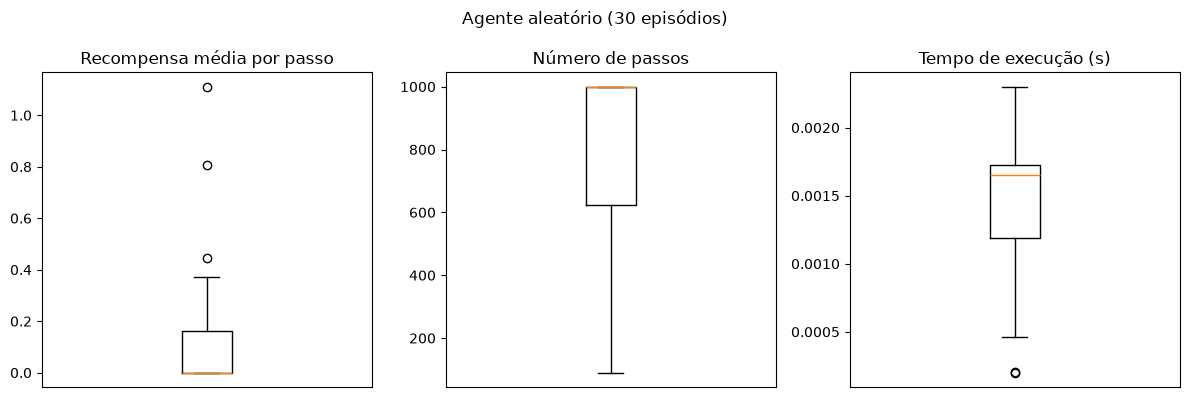

In [8]:
def plot_boxplots(results, title=None):
    metricas = [
        ("reward_per_step", "Recompensa média por passo"),
        ("steps",           "Número de passos"),
        ("execution_time",  "Tempo de execução (s)"),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, (chave, rotulo) in zip(axes, metricas):
        ax.boxplot(results[chave], orientation="vertical")
        ax.set_title(rotulo)
        ax.set_xticks([])
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_boxplots(random_results, title="Agente aleatório (30 episódios)")

**Resultados e Observações - Agente aleatório**

O agente aleatório atingiu o objetivo em 13 dos 30 episódios (43%). Nos restantes 17, o episódio terminou ao fim de 1000 passos sem recompensa. 

| Grandeza | Média | Desvio-padrão |
|---|---|---|
| Número de passos | 781,23 | 316,16 |
| Recompensa média por passo | 0,148 | 0,255 |
| Tempo de execução (s) | 0,0017 | 0,0008 |

- **Número de passos:** a mediana coincide com o limite de 1000 passos, o que significa que mais de metade dos episódios não chegou ao objetivo. 
- **Recompensa média por passo:** a mediana é 0, dado que a maioria dos episódios termina sem recompensa. Os valores mais altos correspondem a episódios em que o objetivo foi atingido rapidamente.
- **Tempo de execução:** é proporcional ao número de passos.